In [1]:
#!pip install ydata-profiling

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
#from ydata_profiling import ProfileReport
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import warnings
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle

In [3]:
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv("loan_approved.csv")

## Basic Checks

In [5]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [6]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    str    
 1   Gender                  601 non-null    str    
 2   Married                 611 non-null    str    
 3   Dependents              599 non-null    str    
 4   Education               614 non-null    str    
 5   Self_Employed           582 non-null    str    
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              592 non-null    float64
 9   Loan_Amount_Term        600 non-null    float64
 10  Credit_History          564 non-null    float64
 11  Property_Area           614 non-null    str    
 12  Loan_Status (Approved)  614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [8]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [9]:
df.describe(include='O')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status (Approved)
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


## EDA

In [10]:
# Task:Perform EDA for the loan approved dataset

In [11]:
# from ydata_profiling import ProfileReport
# profile=ProfileReport(df,title="EDA",explorative=True)
# profile

In [12]:
# profile.to_file('report.html')
# #profile.to_file('report.json')

## Checking for Outliers

<Axes: ylabel='LoanAmount'>

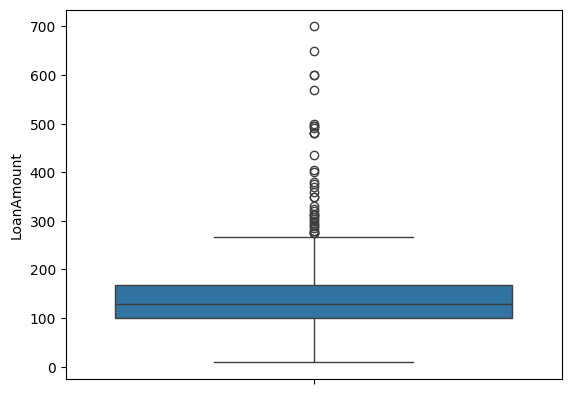

In [13]:
sns.boxplot(df.LoanAmount)

<Axes: ylabel='ApplicantIncome'>

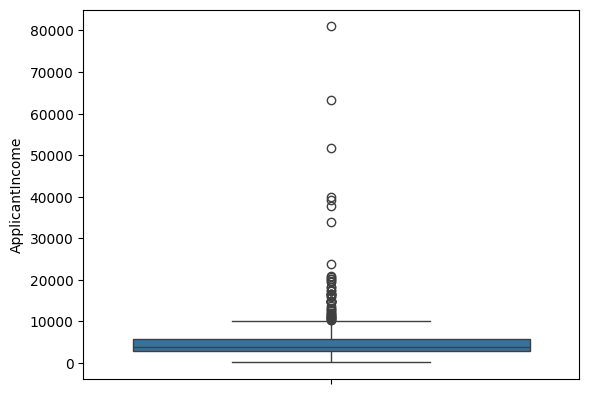

In [14]:
sns.boxplot(df.ApplicantIncome)

<Axes: ylabel='CoapplicantIncome'>

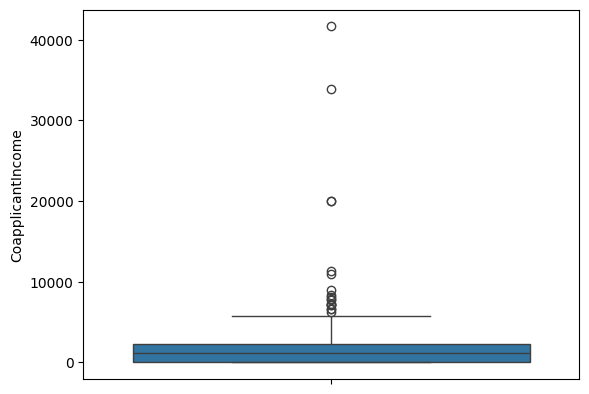

In [15]:
sns.boxplot(df.CoapplicantIncome)

## Data Cleaning
- I see that the outliers are possibly a part of distribution, since extreme values are quite probable in these kind of features. So outliers are not being removed.
- Handling null values is being done.

In [16]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='str')

In [17]:
#Fixing null values
df.loc[df['Gender'].isnull(),'Gender'] = df.Gender.unique()[0]
df.loc[df['Married'].isnull(),'Married'] = df.Married.unique()[0]
df.loc[df['Dependents'].isnull(),'Dependents'] = '0'       # Can also be replaced with df.Dependents.unique()[0]
df.loc[df['Self_Employed'].isnull(),'Self_Employed'] = df.Self_Employed.unique()[0]
df.loc[df['LoanAmount'].isnull(),'LoanAmount'] = df.LoanAmount.mean()
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term'] = df.Loan_Amount_Term.unique()[0]
df.loc[df['Credit_History'].isnull(),'Credit_History'] = df.Credit_History.unique()[0]

In [18]:
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   0
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

<Axes: >

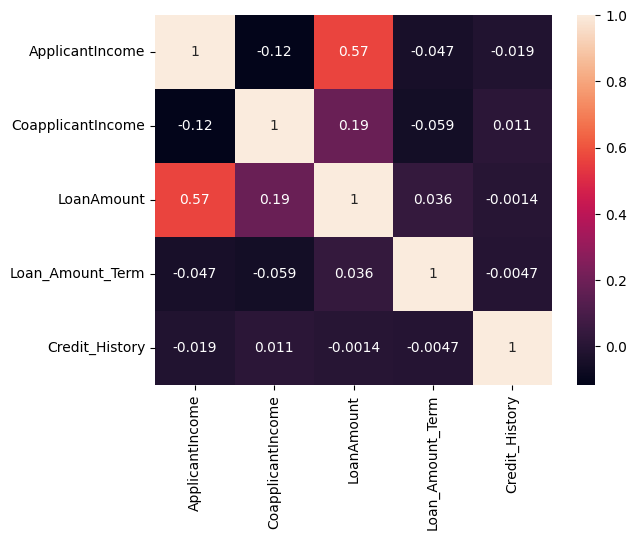

In [19]:
sns.heatmap(df.select_dtypes(include=['int', 'float']).corr(),annot=True)

In [20]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='str')

### Steps of preprocesing for features:
- LabelEncoding for Married
- OrdinalEncoder for Dependents,Education
- One hot encoder for Self Employed,Property_area,Gender
- FunctionTransformer for Loan_Amount_term
- Standard scaler for Applicant Income, CoapplicantIncome and LoanAmount
- Credit histroy will pass through
### Steps of preprocessing for Target/Label
- LabelEncoder for Loan_Status (Approved)

In [21]:
df.Credit_History.unique()

array([1., 0.])

In [22]:
OHE_col=['Self_Employed','Property_Area','Gender']
ss_col=["ApplicantIncome","CoapplicantIncome","LoanAmount"]
function_trasformer_col=["Loan_Amount_Term"]
pass_through_col=['Credit_History']
#we need to define ordinalencoder seperately for every column if we have to define the order of categories
dependents_enc = OrdinalEncoder(categories=[['0', '1', '2', '3+']])
education_enc = OrdinalEncoder(categories=[['Not Graduate','Graduate']])
OE = ['Married']

In [23]:
def div_by_30(x):
    return x/30
custom = FunctionTransformer(div_by_30)

In [24]:
def same(x):
    return x
passthru = FunctionTransformer(same)

In [25]:
preprocessor = ColumnTransformer([('OHE',OneHotEncoder(),OHE_col),
                                  ('SS',StandardScaler(),ss_col),
                                  ('FT',custom,function_trasformer_col),
                                  ('OE',OrdinalEncoder(),OE),
                                  ('do_nothing',passthru,pass_through_col),
                                  ('OE1',dependents_enc,['Dependents']),
                                  ('OE2',education_enc,['Education']),
                                  ])

In [26]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OHE', ...), ('SS', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.

In [27]:
with open('SVM_CT.pkl','wb') as f:
    pickle.dump(preprocessor,f)

In [28]:
with open('Processed_data.pkl','wb') as f:
    pickle.dump(df,f)